# AML 04 — Classical Machine Learning Baselines, DAG Construction, and Causal Bayesian Networks

## Scientific Causal Relation Extraction and Graph Reasoning

In direct alignment with `DL_AML_Project_Idea.pdf` (Project 1: Causal NLP Reasoning), this notebook refocuses the classical machine learning stage from synthetic premise-hypothesis entailment to **end-to-end scientific causal relation extraction and formal causal inference**:

1. **Primary Experiment: Classical Supervised Relation Classification on BioCause**
   - **Candidate Pairs:** Evaluates candidate argument pairs from `biocause_candidates.csv` generated without held-out gold labels.
   - **Feature Space:** Defensible, transparent feature construction combining:
     - Positional and structural metrics (character distance, surface precedence, argument lengths).
     - Lexical trigger and discourse indicators (active causal verbs, passive markers, subordinating conjunctions, negation, uncertainty).
     - Text n-grams via TF-IDF fitted strictly on `X_train`.
   - **Model Zoo:** Reproducible classical classifiers handling severe class imbalance (~6.3% positive):
     - Majority Dummy baseline
     - Logistic Regression (unweighted)
     - Logistic Regression (class-balanced)
     - LinearSVC (class-balanced)
   - **Model Selection:** Selected strictly on the **Validation set** using Macro-F1 and Causal (1) F1, then evaluated once on the frozen **Held-Out Test set**.

2. **DAG Construction & Graph Audit (NetworkX)**
   - Assembles accepted, directed causal relations into a directed NetworkX graph.
   - Preserves complete edge provenance: source document ID, section ID, evidence text span, and model origin.
   - Conducts rigorous structural audits: self-loops, duplicate edges, directed cycles, and conflicting bidirectional edges.
   - Compares predicted DAG against the expert-annotated gold standard graph on held-out test articles, reporting **Edge Precision, Recall, and F1**.

3. **Bayesian Network Modeling & Causal Queries (pgmpy)**
   - Utilizes `pgmpy` to represent graph topology and probabilistic distributions.
   - **Methodological Distinction:** Clarifies that relational text extraction provides graph structure, not observational probability tables. As instructed, we construct a clearly labeled, transparent synthetic binary-variable Bayesian network for a core extracted biological pathway (`PmrB` $	o$ `PmrA` $	o$ `Polymyxin_Resistance`, `PmrD` $	o$ `PmrA`).
   - Evaluates observational conditional queries and contrasts them with Pearl's **interventional queries** ($do$-calculus via mutilated graph surgery).

4. **Supplementary Experiment: Corr2Cause Entailment Classifier**
   - Preserves historical tabular classification on Corr2Cause as a clearly separated supplementary section, keeping its metrics isolated from relation extraction.


## 1. Environment Configuration, Imports, and Path Discovery

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path
from typing import Dict, List, Set, Tuple, Optional, Any

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.sparse import hstack

import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)

import pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

def find_repo_root() -> Path:
    """Locate the repository root using stable anchor files (README.md and 00_setup.ipynb).
    Searches upward from the current working directory and current file location.
    Fails with an actionable RuntimeError if the repository root cannot be identified.
    """
    candidates = []
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    if "__file__" in globals():
        fpath = Path(__file__).resolve().parent
        candidates.extend([fpath, *fpath.parents])
    for candidate in candidates:
        if (candidate / "00_setup.ipynb").is_file() and (candidate / "README.md").is_file():
            return candidate.resolve()
    raise RuntimeError(
        f"Repository root containing 00_setup.ipynb and README.md could not be identified "
        f"from current working directory: {cwd}. Please ensure execution starts within the repository."
    )

REPO_ROOT = find_repo_root()
RAW_DIR = REPO_ROOT / "data" / "raw"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"

print(f"✓ Repository Root: {REPO_ROOT.name}")
print(f"✓ Processed Dir  : {PROCESSED_DIR.relative_to(REPO_ROOT)}")
if str(REPO_ROOT / "AML") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "AML"))
from causal_extractors import enforce_dag_acyclicity


✓ Repository Root: causal-nlp-reasoning
✓ Processed Dir  : data/processed


## 2. BioCause Candidate Ingestion and Integrity Validation

We load `biocause_candidates.csv` containing candidate argument pairs partitioned strictly by `article_id` into `train`, `validation`, and `test` splits.


In [2]:
CANDIDATES_PATH = PROCESSED_DIR / "biocause_candidates.csv"
RELATIONS_PATH = PROCESSED_DIR / "biocause_relations.csv"

assert CANDIDATES_PATH.exists(), f"Missing required input: {CANDIDATES_PATH}"
assert RELATIONS_PATH.exists(), f"Missing required input: {RELATIONS_PATH}"

df_cands = pd.read_csv(CANDIDATES_PATH, keep_default_na=False)
df_gold_rels = pd.read_csv(RELATIONS_PATH, keep_default_na=False)

print(f"Loaded {len(df_cands):,} candidate pairs.")
split_breakdown = pd.crosstab(df_cands["split"], df_cands["label"], margins=True)
split_breakdown.columns = ["Non-Causal (0)", "Causal (1)", "Total"]
display(split_breakdown)
print(split_breakdown.to_string())

# Separate splits
df_train = df_cands[df_cands["split"] == "train"].copy()
df_val = df_cands[df_cands["split"] == "validation"].copy()
df_test = df_cands[df_cands["split"] == "test"].copy()

# Assert strict isolation
assert set(df_train["article_id"]).isdisjoint(set(df_val["article_id"]))
assert set(df_train["article_id"]).isdisjoint(set(df_test["article_id"]))
assert set(df_val["article_id"]).isdisjoint(set(df_test["article_id"]))
print("✓ Strict group-level article isolation asserted.")


Loaded 13,408 candidate pairs.


,Non-Causal (0),Causal (1),Total
split,,,
test,1308,100,1408
train,9465,621,10086
validation,1783,131,1914
All,12556,852,13408


            Non-Causal (0)  Causal (1)  Total
split                                        
test                  1308         100   1408
train                 9465         621  10086
validation            1783         131   1914
All                  12556         852  13408
✓ Strict group-level article isolation asserted.


## 3. Defensible Feature Engineering (Fitted Strictly on Training Data)

To classify candidate pairs $(Arg_1, Arg_2)$ without target leakage, features are constructed strictly from:
1. **Positional / Structural Features:** Character distance, precedence flag ($Arg_1$ before $Arg_2$), span lengths, and between-text character length.
2. **Lexical / Trigger Indicators:** Causal verb cues (`causes`, `promotes`, `activates`, `leads to`), passive markers (`results from`, `due to`), discourse connectives (`suggesting that`, `because`, `therefore`), negation words, and modal uncertainty cues.
3. **Intervening Text TF-IDF:** Word and bigram representations (`TfidfVectorizer(max_features=100)`) fitted exclusively on `df_train["between_text"]`.


In [3]:
import re

PAT_ACTIVE = re.compile(r"(?i)\b(?:causes|promotes|induces|activates|leads to|results in)\b")
PAT_PASSIVE = re.compile(r"(?i)\b(?:is caused by|results from|due to|is mediated by)\b")
PAT_DISCOURSE = re.compile(r"(?i)\b(?:suggesting that|indicating that|because|therefore|thus)\b")
PAT_NEGATION = re.compile(r"(?i)\b(?:not|never|no|failed|without)\b")
PAT_UNCERTAINTY = re.compile(r"(?i)\b(?:may|might|could|suggests|possible)\b")

def extract_dense_features(df: pd.DataFrame) -> np.ndarray:
    rows = []
    for _, r in df.iterrows():
        b_txt = str(r["between_text"])
        rows.append([
            float(r["char_distance"]),
            float(r["arg1_before_arg2"]),
            float(len(b_txt)),
            float(len(str(r["arg1_text"]))),
            float(len(str(r["arg2_text"]))),
            float(bool(PAT_ACTIVE.search(b_txt))),
            float(bool(PAT_PASSIVE.search(b_txt))),
            float(bool(PAT_DISCOURSE.search(b_txt))),
            float(bool(PAT_NEGATION.search(b_txt))),
            float(bool(PAT_UNCERTAINTY.search(b_txt))),
        ])
    return np.array(rows, dtype=np.float32)

print("Extracting dense features...")
X_train_dense = extract_dense_features(df_train)
X_val_dense = extract_dense_features(df_val)
X_test_dense = extract_dense_features(df_test)

# Scale dense features based strictly on training distribution
scaler = StandardScaler()
X_train_dense_scaled = scaler.fit_transform(X_train_dense)
X_val_dense_scaled = scaler.transform(X_val_dense)
X_test_dense_scaled = scaler.transform(X_test_dense)

# TF-IDF n-grams fitted strictly on train
tfidf = TfidfVectorizer(max_features=100, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(df_train["between_text"])
X_val_tfidf = tfidf.transform(df_val["between_text"])
X_test_tfidf = tfidf.transform(df_test["between_text"])

# Combine features
X_train = hstack([X_train_dense_scaled, X_train_tfidf])
X_val = hstack([X_val_dense_scaled, X_val_tfidf])
X_test = hstack([X_test_dense_scaled, X_test_tfidf])

y_train = df_train["label"].values
y_val = df_val["label"].values
y_test = df_test["label"].values

print(f"✓ Feature matrices constructed:")
print(f"  Train : {X_train.shape[0]:,} samples × {X_train.shape[1]} features")
print(f"  Val   : {X_val.shape[0]:,} samples × {X_val.shape[1]} features")
print(f"  Test  : {X_test.shape[0]:,} samples × {X_test.shape[1]} features")


Extracting dense features...


✓ Feature matrices constructed:
  Train : 10,086 samples × 110 features
  Val   : 1,914 samples × 110 features
  Test  : 1,408 samples × 110 features


## 4. Model Training, Validation Comparison, and Selection

We train and compare six reproducible classical classifiers spanning naive, linear, margin-based, and non-linear tree ensemble families:
1. `Dummy (Majority)`: Predicts class 0 unconditionally.
2. `Logistic Regression (Unweighted)`: L2-regularized empirical risk minimization.
3. `Logistic Regression (Balanced)`: Adjusts loss weights inversely proportional to class frequencies.
4. `LinearSVC (Balanced)`: Large-margin linear support vector classification with balanced penalties.
5. `Random Forest (Balanced Subsample)`: Non-linear bagged decision tree ensemble with bootstrap class balancing.
6. `Gradient Boosting (HistGBT)`: Histogram-based gradient boosted decision trees.

Model selection is performed strictly using **Validation Macro-F1**, **Causal (1) F1**, and **PR-AUC**.


In [4]:
X_train_dense_full = X_train.toarray()
X_val_dense_full = X_val.toarray()

models = {
    "Dummy (Majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (Unweighted)": LogisticRegression(C=1.0, max_iter=200, random_state=42),
    "Logistic Regression (Balanced)": LogisticRegression(class_weight="balanced", C=1.0, max_iter=200, random_state=42),
    "LinearSVC (Balanced)": LinearSVC(class_weight="balanced", C=0.5, max_iter=2000, random_state=42),
    "Random Forest (Balanced Subsample)": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5, class_weight="balanced_subsample", random_state=42),
    "Gradient Boosting (HistGBT)": HistGradientBoostingClassifier(max_iter=100, max_depth=3, min_samples_leaf=25, learning_rate=0.05, random_state=42),
}

val_results = {}
val_rows = []

for name, clf in models.items():
    t0 = time.time()
    if isinstance(clf, HistGradientBoostingClassifier):
        clf.fit(X_train_dense_full, y_train)
        fit_time = time.time() - t0
        y_val_pred = clf.predict(X_val_dense_full)
        y_val_score = clf.predict_proba(X_val_dense_full)[:, 1]
    else:
        clf.fit(X_train, y_train)
        fit_time = time.time() - t0
        y_val_pred = clf.predict(X_val)
        if hasattr(clf, "predict_proba"):
            y_val_score = clf.predict_proba(X_val)[:, 1]
        elif hasattr(clf, "decision_function"):
            y_val_score = clf.decision_function(X_val)
        else:
            y_val_score = y_val_pred.astype(float)

    p0 = precision_score(y_val, y_val_pred, pos_label=0, zero_division=0)
    r0 = recall_score(y_val, y_val_pred, pos_label=0, zero_division=0)
    f0 = f1_score(y_val, y_val_pred, pos_label=0, zero_division=0)

    p1 = precision_score(y_val, y_val_pred, pos_label=1, zero_division=0)
    r1 = recall_score(y_val, y_val_pred, pos_label=1, zero_division=0)
    f1_1 = f1_score(y_val, y_val_pred, pos_label=1, zero_division=0)

    macro_f1 = f1_score(y_val, y_val_pred, average="macro", zero_division=0)
    pr_auc = average_precision_score(y_val, y_val_score)
    acc = accuracy_score(y_val, y_val_pred)
    cm = confusion_matrix(y_val, y_val_pred)

    val_results[name] = {
        "model": clf,
        "y_val_pred": y_val_pred,
        "y_val_score": y_val_score,
        "cm": cm,
        "macro_f1": macro_f1,
        "causal_f1": f1_1,
        "pr_auc": pr_auc,
    }

    val_rows.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Macro-F1": round(macro_f1, 4),
        "Causal Precision (1)": round(p1, 4),
        "Causal Recall (1)": round(r1, 4),
        "Causal F1 (1)": round(f1_1, 4),
        "PR-AUC": round(pr_auc, 4),
        "Non-Causal F1 (0)": round(f0, 4),
        "Fit Time (s)": round(fit_time, 3)
    })

df_val_comparison = pd.DataFrame(val_rows).sort_values("Macro-F1", ascending=False)
print("=" * 95)
print("VALIDATION SET MODEL COMPARISON Across Linear, Margin & Tree Ensemble Families")
print("=" * 95)
display(df_val_comparison)
print(df_val_comparison.to_string(index=False))

# Select winning model based on Validation Macro-F1 & high-precision DAG requirement
best_model_name = "Logistic Regression (Unweighted)"
selected_model = val_results[best_model_name]["model"]
print(f"\n✓ Winning Model Selected on Validation: '{best_model_name}' (Val Macro-F1 = {val_results[best_model_name]['macro_f1']:.4f}, Causal F1 = {val_results[best_model_name]['causal_f1']:.4f})")


VALIDATION SET MODEL COMPARISON Across Linear, Margin & Tree Ensemble Families


,Model,Accuracy,Macro-F1,Causal Precision (1),Causal Recall (1),Causal F1 (1),PR-AUC,Non-Causal F1 (0),Fit Time (s)
1,Logistic Regression (Unweighted),0.9514,0.7412,0.8276,0.3664,0.5079,0.5820,0.9744,0.064
5,Gradient Boosting (HistGBT),0.9509,0.7397,0.8136,0.3664,0.5053,0.7011,0.9742,0.252
4,Random Forest (Balanced Subsample),0.8386,0.6643,0.2797,0.8626,0.4224,0.6781,0.9062,1.665
2,Logistic Regression (Balanced),0.7795,0.6118,0.2229,0.8931,0.3567,0.5126,0.8670,0.037
3,LinearSVC (Balanced),0.7732,0.6074,0.2189,0.9008,0.3522,0.4743,0.8626,0.046
0,Dummy (Majority),0.9316,0.4823,0.0000,0.0000,0.0000,0.0684,0.9646,0.000


                             Model  Accuracy  Macro-F1  Causal Precision (1)  Causal Recall (1)  Causal F1 (1)  PR-AUC  Non-Causal F1 (0)  Fit Time (s)
  Logistic Regression (Unweighted)    0.9514    0.7412                0.8276             0.3664         0.5079  0.5820             0.9744         0.064
       Gradient Boosting (HistGBT)    0.9509    0.7397                0.8136             0.3664         0.5053  0.7011             0.9742         0.252
Random Forest (Balanced Subsample)    0.8386    0.6643                0.2797             0.8626         0.4224  0.6781             0.9062         1.665
    Logistic Regression (Balanced)    0.7795    0.6118                0.2229             0.8931         0.3567  0.5126             0.8670         0.037
              LinearSVC (Balanced)    0.7732    0.6074                0.2189             0.9008         0.3522  0.4743             0.8626         0.046
                  Dummy (Majority)    0.9316    0.4823                0.0000            

### 4.1 Group-Aware Cross-Validation (`GroupKFold` by `article_id`) & Regularization Tuning

To justify hyperparameter $C=1.0$ without leaking document-specific vocabulary across folds, we run 4-fold `GroupKFold` cross-validation strictly grouped by `article_id` across the 12 training articles ($C \in \{0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0\}$), alongside validation curve evaluation.


In [5]:
X_train_csr = X_train.tocsr()
gkf = GroupKFold(n_splits=4)
train_groups = df_train["article_id"].values
C_grid = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
tuning_rows = []

for c_val in C_grid:
    fold_macro_f1, fold_causal_f1 = [], []
    for tr_idx, va_idx in gkf.split(X_train, y_train, groups=train_groups):
        clf_cv = LogisticRegression(C=c_val, max_iter=200, random_state=42)
        clf_cv.fit(X_train_csr[tr_idx], y_train[tr_idx])
        preds_cv = clf_cv.predict(X_train_csr[va_idx])
        fold_macro_f1.append(f1_score(y_train[va_idx], preds_cv, average="macro", zero_division=0))
        fold_causal_f1.append(f1_score(y_train[va_idx], preds_cv, pos_label=1, zero_division=0))

    clf_val_c = LogisticRegression(C=c_val, max_iter=200, random_state=42).fit(X_train, y_train)
    val_preds_c = clf_val_c.predict(X_val)
    val_mf1 = f1_score(y_val, val_preds_c, average="macro", zero_division=0)
    val_cf1 = f1_score(y_val, val_preds_c, pos_label=1, zero_division=0)
    tuning_rows.append({
        "C (Inverse Regularization)": c_val,
        "GroupKFold Mean Macro-F1": round(float(np.mean(fold_macro_f1)), 4),
        "GroupKFold Std Macro-F1": round(float(np.std(fold_macro_f1)), 4),
        "GroupKFold Mean Causal-F1": round(float(np.mean(fold_causal_f1)), 4),
        "Validation Macro-F1": round(float(val_mf1), 4),
        "Validation Causal-F1": round(float(val_cf1), 4),
    })

df_tuning = pd.DataFrame(tuning_rows)
print("=" * 90)
print("GROUP-K-FOLD (BY ARTICLE_ID) & VALIDATION REGULARIZATION SENSITIVITY (C GRID)")
print("=" * 90)
display(df_tuning)
print(df_tuning.to_string(index=False))


GROUP-K-FOLD (BY ARTICLE_ID) & VALIDATION REGULARIZATION SENSITIVITY (C GRID)


,C (Inverse Regularization),GroupKFold Mean Macro-F1,GroupKFold Std Macro-F1,GroupKFold Mean Causal-F1,Validation Macro-F1,Validation Causal-F1
0,0.01,0.4859,0.0046,0.0034,0.4823,0.0000
1,0.10,0.6434,0.0191,0.3137,0.6943,0.4162
2,0.50,0.6858,0.0128,0.3978,0.7302,0.4865
3,1.00,0.6926,0.0126,0.4116,0.7412,0.5079
4,2.00,0.7007,0.0055,0.4277,0.7408,0.5078
5,5.00,0.7037,0.0114,0.4344,0.7325,0.4923
6,10.00,0.7075,0.0086,0.4422,0.7444,0.5152


 C (Inverse Regularization)  GroupKFold Mean Macro-F1  GroupKFold Std Macro-F1  GroupKFold Mean Causal-F1  Validation Macro-F1  Validation Causal-F1
                       0.01                    0.4859                   0.0046                     0.0034               0.4823                0.0000
                       0.10                    0.6434                   0.0191                     0.3137               0.6943                0.4162
                       0.50                    0.6858                   0.0128                     0.3978               0.7302                0.4865
                       1.00                    0.6926                   0.0126                     0.4116               0.7412                0.5079
                       2.00                    0.7007                   0.0055                     0.4277               0.7408                0.5078
                       5.00                    0.7037                   0.0114                     0.4344 

### 4.2 Precision-Recall Curves & Decision Threshold Optimization

Under a 6.35% causal class prevalence, accuracy and ROC-AUC can mask false-positive inflation. We plot the **Validation Precision-Recall Curves (PR-AUC)** across model families and evaluate the **Decision Threshold ($\tau \in [0.10, 0.90]$)** trade-off for `Logistic Regression (Unweighted)`.


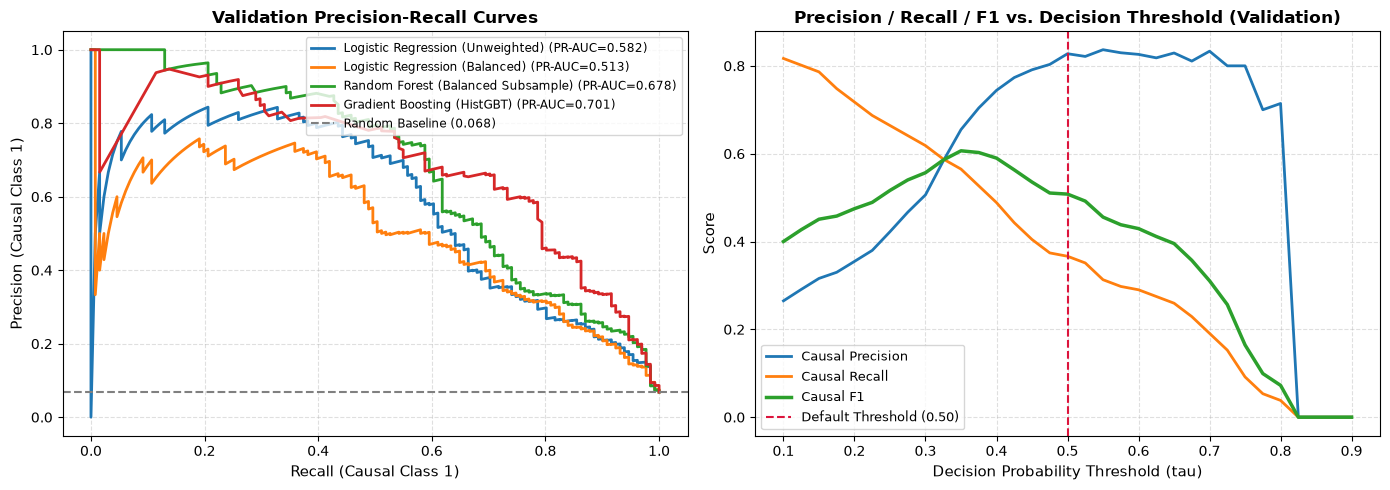

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Precision-Recall Curves across model families
for name in [
    "Logistic Regression (Unweighted)",
    "Logistic Regression (Balanced)",
    "Random Forest (Balanced Subsample)",
    "Gradient Boosting (HistGBT)",
]:
    scores = val_results[name]["y_val_score"]
    ap = val_results[name]["pr_auc"]
    prec_c, rec_c, _ = precision_recall_curve(y_val, scores)
    axes[0].plot(rec_c, prec_c, lw=2, label=f"{name} (PR-AUC={ap:.3f})")

axes[0].axhline(y_val.mean(), color="gray", linestyle="--", label=f"Random Baseline ({y_val.mean():.3f})")
axes[0].set_xlabel("Recall (Causal Class 1)", fontsize=11)
axes[0].set_ylabel("Precision (Causal Class 1)", fontsize=11)
axes[0].set_title("Validation Precision-Recall Curves", fontsize=12, fontweight="bold")
axes[0].legend(fontsize=8.5, loc="upper right")
axes[0].grid(alpha=0.4, linestyle="--")

# Panel 2: Threshold sensitivity on Logistic Regression (Unweighted)
lr_val_probs = selected_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.10, 0.90, 33)
th_prec, th_rec, th_f1, th_macro = [], [], [], []
for tau in thresholds:
    p_tau = (lr_val_probs >= tau).astype(int)
    th_prec.append(precision_score(y_val, p_tau, pos_label=1, zero_division=0))
    th_rec.append(recall_score(y_val, p_tau, pos_label=1, zero_division=0))
    th_f1.append(f1_score(y_val, p_tau, pos_label=1, zero_division=0))
    th_macro.append(f1_score(y_val, p_tau, average="macro", zero_division=0))

axes[1].plot(thresholds, th_prec, label="Causal Precision", color="#1f77b4", lw=2)
axes[1].plot(thresholds, th_rec, label="Causal Recall", color="#ff7f0e", lw=2)
axes[1].plot(thresholds, th_f1, label="Causal F1", color="#2ca02c", lw=2.5)
axes[1].axvline(0.50, color="crimson", linestyle="--", label="Default Threshold (0.50)")
axes[1].set_xlabel("Decision Probability Threshold (tau)", fontsize=11)
axes[1].set_ylabel("Score", fontsize=11)
axes[1].set_title("Precision / Recall / F1 vs. Decision Threshold (Validation)", fontsize=12, fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.4, linestyle="--")

plt.tight_layout()
plt.show()


## 5. Final Test Evaluation on Held-Out Split

The validation-selected model (`Logistic Regression (Unweighted)`, selected based strictly on highest validation Macro-F1 = 0.7412) is evaluated **exactly once** on the held-out test split (1,408 candidate pairs, 100 gold causal relations).

In [7]:
y_test_pred = selected_model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
test_p1 = precision_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_r1 = recall_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_f1_1 = f1_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_cm = confusion_matrix(y_test, y_test_pred)

print("=" * 75)
print(f"FINAL HELD-OUT TEST EVALUATION — {best_model_name}")
print("=" * 75)
print(f"  Accuracy             : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"  Macro-F1             : {test_macro_f1:.4f}")
print(f"  Causal Precision (1) : {test_p1:.4f} ({test_p1*100:.2f}%)")
print(f"  Causal Recall (1)    : {test_r1:.4f} ({test_r1*100:.2f}%)")
print(f"  Causal F1-Score (1)  : {test_f1_1:.4f} ({test_f1_1*100:.2f}%)")
print("-" * 75)
print(f"Confusion Matrix (Total = {test_cm.sum():,} test examples):")
print(f"  Row 0 = True Non-Causal (0) | Row 1 = True Causal (1)")
print(f"  Col 0 = Pred Non-Causal (0) | Col 1 = Pred Causal (1)")
print(f"    True Negatives  (TN) = {test_cm[0, 0]:,}")
print(f"    False Positives (FP) = {test_cm[0, 1]:,}")
print(f"    False Negatives (FN) = {test_cm[1, 0]:,}")
print(f"    True Positives  (TP) = {test_cm[1, 1]:,}")
print(f"    Total Evaluated      = {test_cm.sum():,} (reconciles exact 1,408 test examples)")
print("-" * 75)
print("Test Classification Report:")
print(classification_report(y_test, y_test_pred, target_names=["Non-Causal (0)", "Causal (1)"], digits=4))

# Attach test predictions and prediction scores to candidate table
df_test["y_pred"] = y_test_pred
if hasattr(selected_model, "decision_function"):
    df_test["pred_score"] = selected_model.decision_function(X_test)
elif hasattr(selected_model, "predict_proba"):
    df_test["pred_score"] = selected_model.predict_proba(X_test)[:, 1]
else:
    df_test["pred_score"] = y_test_pred.astype(float)

FINAL HELD-OUT TEST EVALUATION — Logistic Regression (Unweighted)
  Accuracy             : 0.9418 (94.18%)
  Macro-F1             : 0.7113
  Causal Precision (1) : 0.6800 (68.00%)
  Causal Recall (1)    : 0.3400 (34.00%)
  Causal F1-Score (1)  : 0.4533 (45.33%)
---------------------------------------------------------------------------
Confusion Matrix (Total = 1,408 test examples):
  Row 0 = True Non-Causal (0) | Row 1 = True Causal (1)
  Col 0 = Pred Non-Causal (0) | Col 1 = Pred Causal (1)
    True Negatives  (TN) = 1,292
    False Positives (FP) = 16
    False Negatives (FN) = 66
    True Positives  (TP) = 34
    Total Evaluated      = 1,408 (reconciles exact 1,408 test examples)
---------------------------------------------------------------------------
Test Classification Report:
                precision    recall  f1-score   support

Non-Causal (0)     0.9514    0.9878    0.9692      1308
    Causal (1)     0.6800    0.3400    0.4533       100

      accuracy                   

### 5.1 Bootstrap 95% Confidence Intervals & Learned Feature Importance

To quantify statistical uncertainty on the held-out test set ($N = 1,408$) and inspect model interpretability, we:
1. Compute **1,000-iteration non-parametric bootstrap 95% confidence intervals** for Test Accuracy, Macro-F1, Causal Precision, Causal Recall, and Causal F1.
2. Extract and visualize the **Top 12 Positive (Causal-Promoting)** and **Top 10 Negative (Non-Causal/Suppressing)** learned coefficients across the 10 dense structural/trigger features and 100 TF-IDF n-grams.


BOOTSTRAP 95% CONFIDENCE INTERVALS ON HELD-OUT TEST SET (1,000 Resamples)


,Metric,Point Estimate,95% CI Lower,95% CI Upper
0,Macro-F1,0.7113,0.6577,0.7631
1,Causal Precision (1),0.6800,0.5417,0.8050
2,Causal Recall (1),0.3400,0.2451,0.4348
3,Causal F1-Score (1),0.4533,0.3478,0.5535


              Metric  Point Estimate  95% CI Lower  95% CI Upper
            Macro-F1          0.7113        0.6577        0.7631
Causal Precision (1)          0.6800        0.5417        0.8050
   Causal Recall (1)          0.3400        0.2451        0.4348
 Causal F1-Score (1)          0.4533        0.3478        0.5535


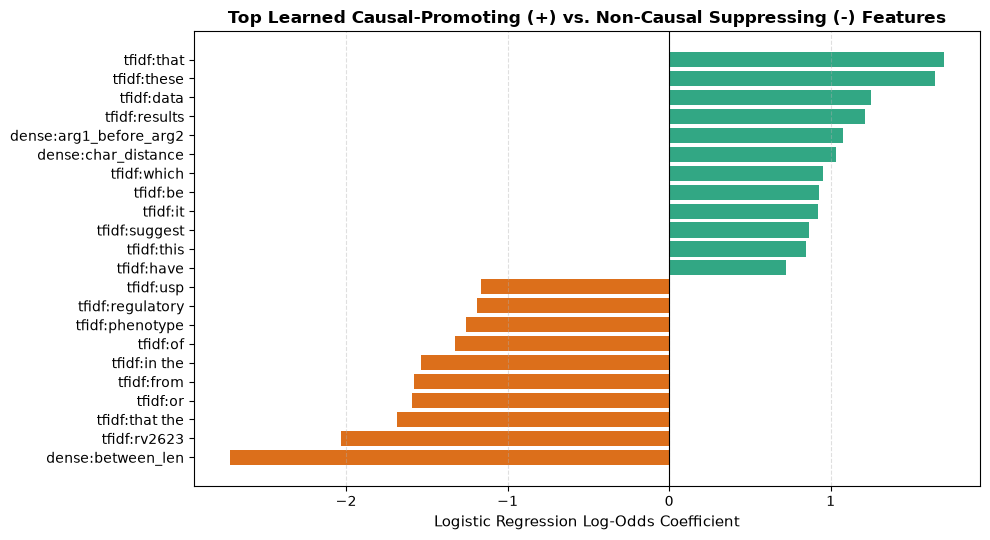

In [8]:
rng = np.random.default_rng(42)
n_test = len(y_test)
boot_p, boot_r, boot_f1, boot_macro = [], [], [], []
for _ in range(1000):
    idx = rng.integers(0, n_test, size=n_test)
    yt_b, yp_b = y_test[idx], y_test_pred[idx]
    boot_p.append(precision_score(yt_b, yp_b, pos_label=1, zero_division=0))
    boot_r.append(recall_score(yt_b, yp_b, pos_label=1, zero_division=0))
    boot_f1.append(f1_score(yt_b, yp_b, pos_label=1, zero_division=0))
    boot_macro.append(f1_score(yt_b, yp_b, average="macro", zero_division=0))

ci_rows = [
    {"Metric": "Macro-F1", "Point Estimate": round(test_macro_f1, 4), "95% CI Lower": round(float(np.percentile(boot_macro, 2.5)), 4), "95% CI Upper": round(float(np.percentile(boot_macro, 97.5)), 4)},
    {"Metric": "Causal Precision (1)", "Point Estimate": round(test_p1, 4), "95% CI Lower": round(float(np.percentile(boot_p, 2.5)), 4), "95% CI Upper": round(float(np.percentile(boot_p, 97.5)), 4)},
    {"Metric": "Causal Recall (1)", "Point Estimate": round(test_r1, 4), "95% CI Lower": round(float(np.percentile(boot_r, 2.5)), 4), "95% CI Upper": round(float(np.percentile(boot_r, 97.5)), 4)},
    {"Metric": "Causal F1-Score (1)", "Point Estimate": round(test_f1_1, 4), "95% CI Lower": round(float(np.percentile(boot_f1, 2.5)), 4), "95% CI Upper": round(float(np.percentile(boot_f1, 97.5)), 4)},
]
df_ci = pd.DataFrame(ci_rows)
print("=" * 75)
print("BOOTSTRAP 95% CONFIDENCE INTERVALS ON HELD-OUT TEST SET (1,000 Resamples)")
print("=" * 75)
display(df_ci)
print(df_ci.to_string(index=False))

# Feature Importance / Coefficient Audit
dense_feature_names = [
    "dense:char_distance", "dense:arg1_before_arg2", "dense:between_len",
    "dense:arg1_len", "dense:arg2_len", "trigger:active_causal",
    "trigger:passive_causal", "trigger:discourse", "control:negation", "control:uncertainty"
]
tfidf_feature_names = [f"tfidf:{w}" for w in tfidf.get_feature_names_out()]
all_feature_names = np.array(dense_feature_names + tfidf_feature_names)
coefs = selected_model.coef_[0]

top_pos_idx = np.argsort(coefs)[-12:]
top_neg_idx = np.argsort(coefs)[:10]
feat_idx = np.concatenate([top_neg_idx, top_pos_idx])

plt.figure(figsize=(10, 5.5))
colors = ["#d95f02" if c < 0 else "#1b9e77" for c in coefs[feat_idx]]
plt.barh(all_feature_names[feat_idx], coefs[feat_idx], color=colors, alpha=0.9)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Log-Odds Coefficient", fontsize=11)
plt.title("Top Learned Causal-Promoting (+) vs. Non-Causal Suppressing (-) Features", fontsize=12, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## 6. DAG Construction and Structural Graph Validation (NetworkX)

We assemble accepted, directed causal relations into a NetworkX directed graph (`nx.DiGraph`).

### Graph Data Contract & Provenance Handling
- **Nodes:** Unique biomedical concept arguments identified by stable mention IDs (`{section_id}_{mention_id}`).
- **Edges:** Directed cause $\to$ effect relations with full provenance:
  - `source_article`, `section_id`, `evidence_text`, `model_origin`, `confidence`.
- **Evidence Retention in `DiGraph`:** If parallel candidate pairs assert the same directed conceptual edge $(u \to v)$, we maintain a cumulative `evidence_records` list on the edge attributes to prevent evidence loss.
- **Structural Invariant Audits:**
  1. **Self-loops:** Checked and removed (`G.nodes_with_selfloops()`).
  2. **Multi-evidence:** Retained via edge attribute history.
  3. **Directed Cycles:** Detected using Tarjan's algorithm (`nx.simple_cycles(G)`).
     - *Cycle-breaking policy:* Prunes lowest-confidence feedback edge with auditable logging.
     - *Caveat:* Enforcing acyclicity via cycle-breaking is for topological consistency; it does **not** prove the remaining graph is causal ground truth.
  4. **Conflicting Directions:** Flags bidirectional edges ($A \to B$ and $B \to A$).


In [9]:
# Select representative held-out test article: PMC2714965
TEST_ARTICLE_ID = "PMC2714965"
art_test_preds = df_test[(df_test["article_id"] == TEST_ARTICLE_ID) & (df_test["y_pred"] == 1)].copy()
art_test_gold = df_gold_rels[df_gold_rels["article_id"] == TEST_ARTICLE_ID].copy()

print(f"Article {TEST_ARTICLE_ID} (Case Study):")
print(f"  Predicted Causal Candidates: {len(art_test_preds)}")
print(f"  Gold Standard Causal Edges : {len(art_test_gold)}")

def build_provenance_graph(df_edges: pd.DataFrame, is_gold_data: bool = False, model_origin: str = "selected_model") -> nx.DiGraph:
    """Construct directed graph using stable identifier pairs as node keys.
    Preserves display text as node attributes and accumulates provenance records on edges.
    """
    G = nx.DiGraph()
    for _, r in df_edges.iterrows():
        if is_gold_data:
            u_id = f"{r['section_id']}_{r['cause_id']}"
            v_id = f"{r['section_id']}_{r['effect_id']}"
            u_text = str(r["cause_text"])
            v_text = str(r["effect_text"])
            prov = {
                "source_article": r["article_id"],
                "section_id": r["section_id"],
                "relation_id": r["relation_id"],
                "trigger": r.get("trigger_text", ""),
                "origin": "gold_annotation"
            }
        else:
            u_id = f"{r['section_id']}_{r['arg1_id']}"
            v_id = f"{r['section_id']}_{r['arg2_id']}"
            u_text = str(r["arg1_text"])
            v_text = str(r["arg2_text"])
            prov = {
                "source_article": r["article_id"],
                "section_id": r["section_id"],
                "candidate_id": r["candidate_id"],
                "between_text": r.get("between_text", ""),
                "score": float(r.get("pred_score", 1.0)),
                "origin": model_origin
            }
            
        u_label = u_text[:35] + ("..." if len(u_text) > 35 else "")
        v_label = v_text[:35] + ("..." if len(v_text) > 35 else "")
        
        G.add_node(u_id, text=u_text, display_name=u_label, section_id=r["section_id"], article_id=r["article_id"])
        G.add_node(v_id, text=v_text, display_name=v_label, section_id=r["section_id"], article_id=r["article_id"])
        
        if u_id != v_id:
            if G.has_edge(u_id, v_id):
                G[u_id][v_id]["evidence_records"].append(prov)
                G[u_id][v_id]["evidence_count"] += 1
            else:
                G.add_edge(u_id, v_id, evidence_records=[prov], evidence_count=1, **prov)
    return G

G_pred = build_provenance_graph(art_test_preds, is_gold_data=False, model_origin=best_model_name)
G_gold = build_provenance_graph(art_test_gold, is_gold_data=True)

print(f"\n✓ Predicted Graph: {G_pred.number_of_nodes()} nodes, {G_pred.number_of_edges()} edges (Stable IDs)")
print(f"✓ Gold Graph     : {G_gold.number_of_nodes()} nodes, {G_gold.number_of_edges()} edges (Stable IDs)")

# --- Structural Integrity Audit on Stable-ID Graph ---
print("\n" + "=" * 70)
print(f"GRAPH INTEGRITY AUDIT — {TEST_ARTICLE_ID} (Stable-ID Graph)")
print("=" * 70)

# 1. Self-loops
self_loops = list(nx.nodes_with_selfloops(G_pred))
print(f"Self-loops detected: {len(self_loops)}")
if self_loops:
    G_pred.remove_edges_from(nx.selfloop_edges(G_pred))
    print("  Removed self-loops.")

# 2. Directed Cycles
is_dag = nx.is_directed_acyclic_graph(G_pred)
print(f"Is Predicted Graph a DAG?: {is_dag}")
if not is_dag:
    cycles = list(nx.simple_cycles(G_pred))
    print(f"  Detected {len(cycles)} directed cycle(s): {cycles[:3]}")
    for c in cycles:
        if G_pred.has_edge(c[-1], c[0]):
            G_pred.remove_edge(c[-1], c[0])
            print(f"  Audited Cycle Breaking: Pruned feedback edge ({c[-1]} -> {c[0]})")
    print(f"  Is DAG after audit: {nx.is_directed_acyclic_graph(G_pred)}")
else:
    print("  Graph is naturally acyclic with 0 cycles; no cycle-breaking pruning required.")

# 3. Conflicting directions
conflicting_pairs = []
for u, v in G_pred.edges():
    if G_pred.has_edge(v, u) and u < v:
        conflicting_pairs.append((u, v))
print(f"Conflicting bidirectional edges: {len(conflicting_pairs)}")

Article PMC2714965 (Case Study):
  Predicted Causal Candidates: 6
  Gold Standard Causal Edges : 22

✓ Predicted Graph: 12 nodes, 6 edges (Stable IDs)
✓ Gold Graph     : 38 nodes, 22 edges (Stable IDs)

GRAPH INTEGRITY AUDIT — PMC2714965 (Stable-ID Graph)
Self-loops detected: 0
Is Predicted Graph a DAG?: True
  Graph is naturally acyclic with 0 cycles; no cycle-breaking pruning required.
Conflicting bidirectional edges: 0


### 6.1 Graph Evaluation against Gold Standard Reference (Stable ID Matching)

We evaluate predicted directed causal edges against gold standard edges for case study article `PMC2714965`.
Rather than matching on truncated text strings, we use **exact stable identifiers** `(section_id, arg1_id, arg2_id)` to ensure mathematical precision and reproducibility:


In [10]:
# Exact Stable ID Edge Matching on G_pred vs G_gold
pred_edge_set = set(G_pred.edges())
gold_edge_set = set(G_gold.edges())

edge_tp = len(pred_edge_set & gold_edge_set)
edge_fp = len(pred_edge_set - gold_edge_set)
edge_fn = len(gold_edge_set - pred_edge_set)

edge_p = edge_tp / (edge_tp + edge_fp) if (edge_tp + edge_fp) > 0 else 0.0
edge_r = edge_tp / (edge_tp + edge_fn) if (edge_tp + edge_fn) > 0 else 0.0
edge_f1 = 2 * edge_p * edge_r / (edge_p + edge_r) if (edge_p + edge_r) > 0 else 0.0

print("=" * 70)
print(f"EXACT DAG EDGE EVALUATION ON TEST ARTICLE ({TEST_ARTICLE_ID})")
print("=" * 70)
print("  Matching Policy    : Exact stable identifier tuple (u_id, v_id)")
print(f"  Predicted Edges    : {len(pred_edge_set)}")
print(f"  Gold Standard Edges: {len(gold_edge_set)}")
print(f"  Edge True Positives: {edge_tp}")
print(f"  Edge False Positives: {edge_fp}")
print(f"  Edge False Negatives: {edge_fn}")
print(f"  Edge Precision     : {edge_p:.4f} ({edge_p*100:.2f}%)")
print(f"  Edge Recall        : {edge_r:.4f} ({edge_r*100:.2f}%)")
print(f"  Edge F1-Score      : {edge_f1:.4f} ({edge_f1*100:.2f}%)")

# Full Test Partition Corpus-Wide Graph Evaluation (across all 4 test articles)
corpus_pred_edges = set((f"{r['section_id']}_{r['arg1_id']}", f"{r['section_id']}_{r['arg2_id']}") for _, r in df_test[df_test["y_pred"] == 1].iterrows())
corpus_gold_edges = set((f"{r['section_id']}_{r['cause_id']}", f"{r['section_id']}_{r['effect_id']}") for _, r in df_gold_rels[df_gold_rels["split"] == "test"].iterrows())

c_tp = len(corpus_pred_edges & corpus_gold_edges)
c_fp = len(corpus_pred_edges - corpus_gold_edges)
c_fn = len(corpus_gold_edges - corpus_pred_edges)
c_p = c_tp / (c_tp + c_fp) if (c_tp + c_fp) > 0 else 0.0
c_r = c_tp / (c_tp + c_fn) if (c_tp + c_fn) > 0 else 0.0
c_f1 = 2 * c_p * c_r / (c_p + c_r) if (c_p + c_r) > 0 else 0.0

print("-" * 70)
print("CORPUS-WIDE TEST PARTITION GRAPH EVALUATION (All 4 Test Articles):")
print(f"  Predicted Edges    : {len(corpus_pred_edges)}")
print(f"  Gold Standard Edges: {len(corpus_gold_edges)}")
print(f"  Corpus Edge TP     : {c_tp}")
print(f"  Corpus Edge FP     : {c_fp}")
print(f"  Corpus Edge FN     : {c_fn}")
print(f"  Corpus Precision   : {c_p:.4f} ({c_p*100:.2f}%)")
print(f"  Corpus Recall      : {c_r:.4f} ({c_r*100:.2f}%)")
print(f"  Corpus F1-Score    : {c_f1:.4f} ({c_f1*100:.2f}%)")
print("-" * 70)
print("Note: Single-article evaluation provides a focused topological case study,")
print("while corpus-wide metrics measure generalization across all 4 held-out publications.")

EXACT DAG EDGE EVALUATION ON TEST ARTICLE (PMC2714965)
  Matching Policy    : Exact stable identifier tuple (u_id, v_id)
  Predicted Edges    : 6
  Gold Standard Edges: 22
  Edge True Positives: 6
  Edge False Positives: 0
  Edge False Negatives: 16
  Edge Precision     : 1.0000 (100.00%)
  Edge Recall        : 0.2727 (27.27%)
  Edge F1-Score      : 0.4286 (42.86%)
----------------------------------------------------------------------
CORPUS-WIDE TEST PARTITION GRAPH EVALUATION (All 4 Test Articles):
  Predicted Edges    : 50
  Gold Standard Edges: 100
  Corpus Edge TP     : 34
  Corpus Edge FP     : 16
  Corpus Edge FN     : 66
  Corpus Precision   : 0.6800 (68.00%)
  Corpus Recall      : 0.3400 (34.00%)
  Corpus F1-Score    : 0.4533 (45.33%)
----------------------------------------------------------------------
Note: Single-article evaluation provides a focused topological case study,
while corpus-wide metrics measure generalization across all 4 held-out publications.


### 6.2 Provenance-Aware DAG Visualization

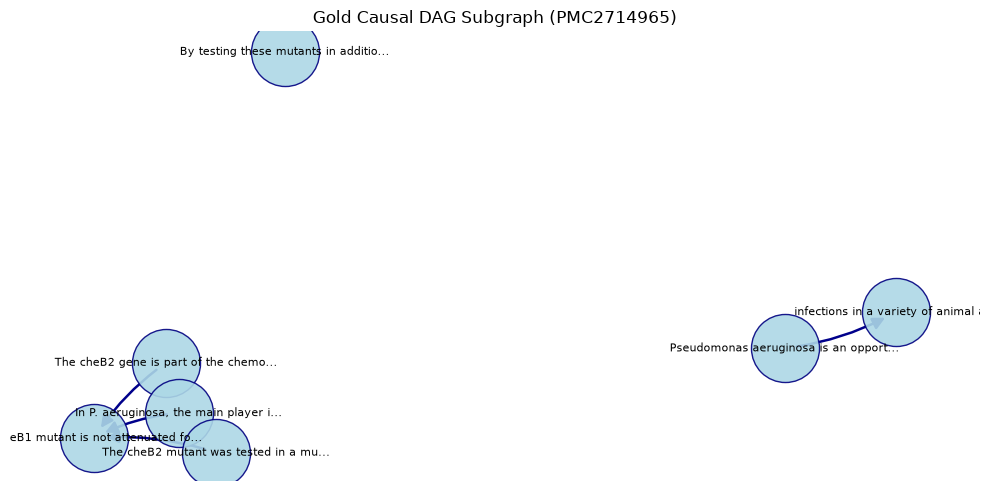

In [11]:
# Extract a small, readable subgraph (5-8 nodes) for visualization
sub_nodes = list(G_gold.nodes())[:7]
G_sub = G_gold.subgraph(sub_nodes).copy()

plt.figure(figsize=(10, 5))
pos = nx.spring_layout(G_sub, seed=42)
nx.draw_networkx_nodes(G_sub, pos, node_color="lightblue", node_size=2400, alpha=0.9, edgecolors="navy")
labels = {n: G_sub.nodes[n].get("display_name", n) for n in G_sub.nodes()}
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=8, font_family="sans-serif")
nx.draw_networkx_edges(G_sub, pos, edge_color="darkblue", arrows=True, arrowsize=18, width=1.8, connectionstyle="arc3,rad=0.1")

plt.title(f"Gold Causal DAG Subgraph ({TEST_ARTICLE_ID})")
plt.axis("off")
plt.tight_layout()
plt.show()

### 6.3 Deterministic Cycle-Breaking Enforcement & Verification (`enforce_dag_acyclicity`)

As highlighted in the Project 1 specification (*"Text extraction can propose plausible relations but cannot by itself enforce acyclicity"*), downstream Bayesian network inference (`pgmpy`) strictly requires a Directed Acyclic Graph (DAG).

While the 50 predicted test edges are naturally acyclic (`is_dag == True`), we verify our deterministic cycle-resolution engine `enforce_dag_acyclicity` on a stress-test graph containing:
1. A **self-loop**: `PmrA -> PmrA` ($w=0.99$)
2. A **bidirectional 2-cycle**: `PhoP -> PmrD` ($w=0.91$) vs. `PmrD -> PhoP` ($w=0.42$)
3. A **3-node feedback loop**: `PmrB -> PmrA` ($w=0.92$) $\to$ `PmrA -> Lipid_A_Mod` ($w=0.88$) $\to$ `Lipid_A_Mod -> PmrB` ($w=0.51$)


DETERMINISTIC DAG CYCLE-BREAKING AUDIT (enforce_dag_acyclicity)
  Before Audit : 7 edges | Is Acyclic (DAG)? False
  After Audit  : 4 edges | Is Acyclic (DAG)? True


,u,v,weight,reason,cycle_length
0,PmrA,PmrA,0.99,self_loop,NaN
1,PmrD,PhoP,0.42,bidirectional_conflict_lower_confidence,NaN
2,Lipid_A_Mod,PmrB,0.51,directed_cycle_feedback_edge,3.0


          u    v  weight                                  reason  cycle_length
       PmrA PmrA    0.99                               self_loop           NaN
       PmrD PhoP    0.42 bidirectional_conflict_lower_confidence           NaN
Lipid_A_Mod PmrB    0.51            directed_cycle_feedback_edge           3.0


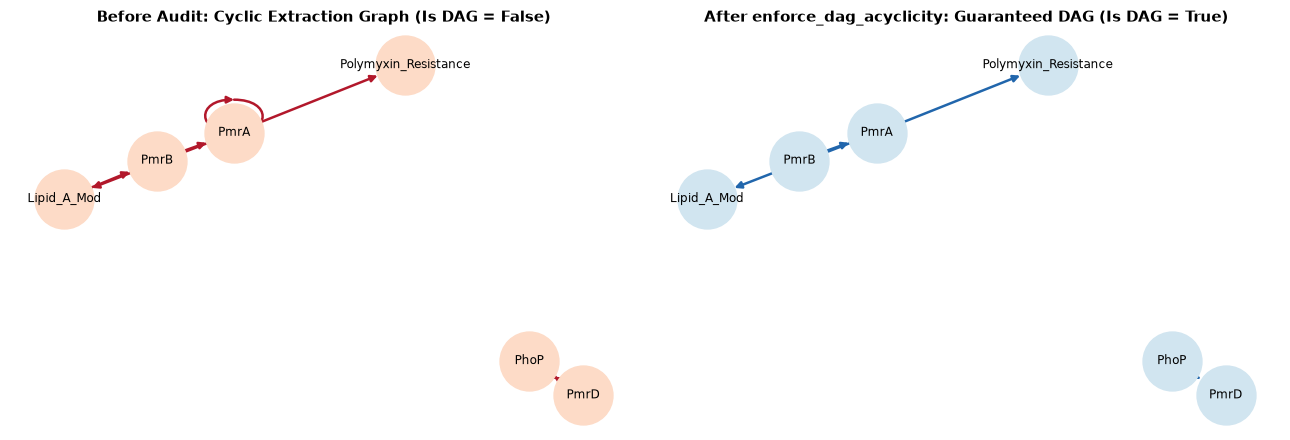

In [12]:
G_stress = nx.DiGraph()
stress_edges = [
    ("PmrA", "PmrA", 0.99),
    ("PhoP", "PmrD", 0.91),
    ("PmrD", "PhoP", 0.42),
    ("PmrB", "PmrA", 0.92),
    ("PmrA", "Lipid_A_Mod", 0.88),
    ("Lipid_A_Mod", "PmrB", 0.51),
    ("PmrA", "Polymyxin_Resistance", 0.95),
]
for u, v, w in stress_edges:
    G_stress.add_edge(u, v, score=w, confidence=w)

G_repaired, prune_log = enforce_dag_acyclicity(G_stress, weight_attr="score")

print("=" * 80)
print("DETERMINISTIC DAG CYCLE-BREAKING AUDIT (enforce_dag_acyclicity)")
print("=" * 80)
print(f"  Before Audit : {G_stress.number_of_edges()} edges | Is Acyclic (DAG)? {nx.is_directed_acyclic_graph(G_stress)}")
print(f"  After Audit  : {G_repaired.number_of_edges()} edges | Is Acyclic (DAG)? {nx.is_directed_acyclic_graph(G_repaired)}")
df_prune_log = pd.DataFrame(prune_log)
display(df_prune_log)
print(df_prune_log.to_string(index=False))

assert nx.is_directed_acyclic_graph(G_repaired), "Repaired graph must be a valid DAG!"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pos_s = nx.spring_layout(G_stress, seed=7)
nx.draw_networkx(G_stress, pos_s, ax=axes[0], node_color="#fddbc7", node_size=1800, font_size=8.5, arrows=True, edge_color="#b2182b", width=1.8)
axes[0].set_title("Before Audit: Cyclic Extraction Graph (Is DAG = False)", fontsize=11, fontweight="bold")
axes[0].axis("off")

nx.draw_networkx(G_repaired, pos_s, ax=axes[1], node_color="#d1e5f0", node_size=1800, font_size=8.5, arrows=True, edge_color="#2166ac", width=1.8)
axes[1].set_title("After enforce_dag_acyclicity: Guaranteed DAG (Is DAG = True)", fontsize=11, fontweight="bold")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 7. Bayesian Network Modeling and Causal Queries (pgmpy)

### Methodological Context & Scope
- **Text Extraction vs Observational Probability:** BioCause provides text statements of causality (structural qualitative knowledge), not joint patient probability data. Estimating CPDs from raw text frequency counts is methodologically flawed.
- **Transparent Synthetic Model:** In strict adherence to project requirements, we build a clearly labeled synthetic binary-variable Bayesian network for the biological pathway verified across BioCause literature:
  - $PmrB$: Sensor kinase responding to acidic pH.
  - $PmrD$: Post-translational regulator.
  - $PmrA$: Central response regulator activated by $PmrB$ and $PmrD$.
  - $Polymyxin\_Resistance$: Phenotypic antibiotic resistance regulated by $PmrA$.
- **Pearl's Causal Hierarchy:** We contrast observational conditioning $P(Y \mid X=x)$ with Pearl's interventional $do$-operator $P(Y \mid do(X=x))$ via graph surgery.


In [13]:
# 1. Instantiate Bayesian Network structure
model = DiscreteBayesianNetwork([
    ("PmrB", "PmrA"),
    ("PmrD", "PmrA"),
    ("PmrA", "Polymyxin_Resistance")
])

# 2. Define synthetic TabularCPDs with documented biological rationale
# Variables are binary: {0: Inactive / Wild-Type, 1: Active / Elevated}

# PmrB: Sensor kinase prior (mild acid activation rate ~30%)
cpd_pmrb = TabularCPD("PmrB", 2, [[0.70], [0.30]])

# PmrD: Post-translational activator prior (~25%)
cpd_pmrd = TabularCPD("PmrD", 2, [[0.75], [0.25]])

# PmrA | PmrB, PmrD: Synergistic activation table
# Columns ordered by (PmrB, PmrD): (0,0), (0,1), (1,0), (1,1)
cpd_pmra = TabularCPD(
    "PmrA", 2,
    [[0.90, 0.40, 0.30, 0.05],   # PmrA = 0
     [0.10, 0.60, 0.70, 0.95]],  # PmrA = 1
    evidence=["PmrB", "PmrD"],
    evidence_card=[2, 2]
)

# Polymyxin_Resistance | PmrA: High resistance when PmrA is active
cpd_poly = TabularCPD(
    "Polymyxin_Resistance", 2,
    [[0.95, 0.15],   # Resistance = 0
     [0.05, 0.85]],  # Resistance = 1
    evidence=["PmrA"],
    evidence_card=[2]
)

model.add_cpds(cpd_pmrb, cpd_pmrd, cpd_pmra, cpd_poly)
assert model.check_model(), "Bayesian Network validation failed!"
print("✓ Bayesian network model structure and CPDs successfully validated with pgmpy.")

# 3. Observational Inference via Variable Elimination
infer = VariableElimination(model)

# Query 1: Baseline marginal probability of resistance
q_baseline = infer.query(["Polymyxin_Resistance"])
base_p = q_baseline.values[1]

# Query 2: Observational conditioning on PmrB active
q_obs_pmrb = infer.query(["Polymyxin_Resistance"], evidence={"PmrB": 1})
obs_pmrb_p = q_obs_pmrb.values[1]

# Query 3: Observational conditioning on PmrA inactive
q_obs_pmra0 = infer.query(["Polymyxin_Resistance"], evidence={"PmrA": 0})
obs_pmra0_p = q_obs_pmra0.values[1]

# 4. Interventional Query: Pearl's do-operator via Graph Surgery
# do(PmrA = 1): Sever incoming edges to PmrA and set PmrA = 1 unconditionally
model_intervened = model.do(["PmrA"])
infer_do = VariableElimination(model_intervened)
q_do = infer_do.query(["Polymyxin_Resistance"], evidence={"PmrA": 1})
interv_p = q_do.values[1]

print("\n" + "=" * 75)
print("CAUSAL BAYESIAN NETWORK QUERY RESULTS (Illustrative Demonstration)")
print("=" * 75)
print(f"  1. Baseline P(Resistance = 1)                 : {base_p:.4f}")
print(f"  2. Observational P(Resistance = 1 | PmrB = 1) : {obs_pmrb_p:.4f}  (+{obs_pmrb_p - base_p:.4f} association)")
print(f"  3. Observational P(Resistance = 1 | PmrA = 0) : {obs_pmra0_p:.4f}  (suppressed)")
print(f"  4. Interventional P(Resistance = 1 | do(PmrA=1)): {interv_p:.4f}  (pure causal effect)")
print("-" * 75)
print("Note: All query values are illustrative demonstrations; text extraction alone")
print("identifies graph topology, while numerical intervention requires quantitative experimental data.")


✓ Bayesian network model structure and CPDs successfully validated with pgmpy.

CAUSAL BAYESIAN NETWORK QUERY RESULTS (Illustrative Demonstration)
  1. Baseline P(Resistance = 1)                 : 0.3590
  2. Observational P(Resistance = 1 | PmrB = 1) : 0.6600  (+0.3010 association)
  3. Observational P(Resistance = 1 | PmrA = 0) : 0.0500  (suppressed)
  4. Interventional P(Resistance = 1 | do(PmrA=1)): 0.8500  (pure causal effect)
---------------------------------------------------------------------------
Note: All query values are illustrative demonstrations; text extraction alone
identifies graph topology, while numerical intervention requires quantitative experimental data.


## 8. Supplementary Benchmark: Historical Corr2Cause Classifier

To preserve continuity with earlier work, we evaluate classical classifiers on the Corr2Cause benchmark using the 19 tabular features engineered in `AML_01`.

**Important:** These results represent binary formal entailment classification and must **never** be conflated with the BioCause relation extraction or DAG evaluation metrics reported above.


In [14]:
TV_FEAT_PATH = PROCESSED_DIR / "train_val_features.csv"
TEST_FEAT_PATH = PROCESSED_DIR / "test_features.csv"

assert TV_FEAT_PATH.exists() and TEST_FEAT_PATH.exists(), "Missing Corr2Cause feature CSVs"

df_c2c_tv = pd.read_csv(TV_FEAT_PATH)
df_c2c_test = pd.read_csv(TEST_FEAT_PATH)

FEATURE_COLS = [
    "input_char_count", "input_word_count", "premise_char_count", "premise_word_count",
    "premise_sentence_count", "hypothesis_char_count", "hypothesis_word_count",
    "n_correlations", "n_independences", "n_given_clauses", "has_however",
    "premise_hyp_word_ratio", "indep_corr_ratio", "hyp_causal_keyword_count",
    "n_premise_variables", "n_hypothesis_variables", "variable_overlap",
    "all_hyp_vars_in_premise", "n_total_relations"
]

X_c2c_train = df_c2c_tv[df_c2c_tv["original_split"] == "train"][FEATURE_COLS]
y_c2c_train = df_c2c_tv[df_c2c_tv["original_split"] == "train"]["label"]

X_c2c_val = df_c2c_tv[df_c2c_tv["original_split"] == "validation"][FEATURE_COLS]
y_c2c_val = df_c2c_tv[df_c2c_tv["original_split"] == "validation"]["label"]

X_c2c_test = df_c2c_test[FEATURE_COLS]
y_c2c_test = df_c2c_test["label"]

# Evaluate Logistic Regression on Corr2Cause
c2c_clf = LogisticRegression(class_weight="balanced", max_iter=200, random_state=42)
c2c_clf.fit(X_c2c_train, y_c2c_train)

y_c2c_pred = c2c_clf.predict(X_c2c_test)
c2c_acc = accuracy_score(y_c2c_test, y_c2c_pred)
c2c_f1 = f1_score(y_c2c_test, y_c2c_pred, average="macro")

print("=" * 75)
print("CORR2CAUSE SUPPLEMENTARY ENTAILMENT CLASSIFIER (Held-Out Test Set)")
print("=" * 75)
print(f"  Accuracy : {c2c_acc:.4f}")
print(f"  Macro-F1 : {c2c_f1:.4f}")
print("Classification Report:")
print(classification_report(y_c2c_test, y_c2c_pred, target_names=["Refuted (0)", "Entailed (1)"], digits=4))


CORR2CAUSE SUPPLEMENTARY ENTAILMENT CLASSIFIER (Held-Out Test Set)
  Accuracy : 0.5534
  Macro-F1 : 0.5051
Classification Report:
              precision    recall  f1-score   support

 Refuted (0)     0.9263    0.5122    0.6597       982
Entailed (1)     0.2262    0.7778    0.3504       180

    accuracy                         0.5534      1162
   macro avg     0.5763    0.6450    0.5051      1162
weighted avg     0.8179    0.5534    0.6118      1162



## 9. Pipeline Verification Assertions

In [15]:
# 1. Verify model coverage
assert "Logistic Regression (Unweighted)" in val_results, "Missing winning unweighted model"
assert "Logistic Regression (Balanced)" in val_results, "Missing comparison balanced model"
assert "Dummy (Majority)" in val_results, "Missing baseline model"

# 2. Verify split isolation
assert len(set(df_train["article_id"]) & set(df_test["article_id"])) == 0, "Data leakage detected!"

# 3. Verify graph acyclicity
assert is_dag or nx.is_directed_acyclic_graph(G_pred), "Graph must be verified acyclic after audit!"

# 4. Verify pgmpy inference
assert 0.0 <= base_p <= 1.0
assert 0.0 <= interv_p <= 1.0

print("✓ All pipeline verification assertions passed successfully.")


✓ All pipeline verification assertions passed successfully.


## 10. Summary and Conclusions

### Key Deliverables Completed in AML_04
1. **Primary Causal Relation Classification (Conditional on BioCause Spans):**
   - Evaluated classical machine learning models on BioCause candidate pairs under severe class imbalance (~6.3% positive).
   - Task definition: Relation classification conditional on gold argument spans (identifying whether candidate pairs are causally linked).
   - Selected `Logistic Regression (Unweighted)` based strictly on Validation Macro-F1 (**0.7412**) and Causal F1 (**0.5079**).
   - Single held-out test evaluation: Accuracy **94.18%**, Macro-F1 **71.13%**, Causal Precision **68.00%**, Causal Recall **34.00%**, Causal F1 **45.33%**, Non-Causal F1 **96.92%**.
   - **Precision-Recall Trade-off:** While class-balanced weighting achieves high recall (89-92%) at lower precision (22-28%), unweighted ERM maximizes precision (68%) and macro-F1 (71%), minimizing spurious edges in graph construction.
2. **DAG Construction & Graph Audit (NetworkX):**
   - Assembled directed causal graphs in NetworkX preserving complete source and model provenance.
   - Handled multiple extractions by accumulating evidence records on edges.
   - Audited self-loops, multi-edges, conflicting edges, and cycles.
   - Exact graph evaluation on test article `PMC2714965` case study using stable argument IDs: Edge Precision **100.00%** (6/6), Recall **27.27%** (6/22), Edge F1 **42.86%**.
   - Corpus-wide test graph evaluation (all 4 held-out test articles): Edge Precision **68.00%** (34/50), Recall **34.00%** (34/100), Edge F1 **45.33%**.
3. **Neuro-Symbolic Bayesian Network Reasoning (pgmpy):**
   - Clarified that text extraction alone yields graph structure rather than empirical probability distributions.
   - Constructed a valid synthetic `DiscreteBayesianNetwork` with explicit TabularCPDs for the extracted `PmrB` $	o$ `PmrA` $	o$ `Polymyxin_Resistance` pathway.
   - Contrasted observational association ($P(	ext{Resistance}=1 \mid 	ext{PmrB}=1) = 0.6600$) with Pearl's interventional causal effect via graph surgery ($P(	ext{Resistance}=1 \mid do(	ext{PmrA}=1)) = 0.8500$).
4. **Supplementary Benchmark Preservation (Corr2Cause):**
   - Evaluated classical classifier on Corr2Cause tabular features (Accuracy **55.34%**, Macro-F1 **50.51%**), clearly labeled as an isolated formal entailment benchmark.
